# CaSR chemical research workbench

**A runnable research notebook, with real assay data and actual calculations.**

สมุดงานนี้สร้างโครงสร้างสารและฝึกแบบจำลองใหม่จากข้อมูลที่ตีพิมพ์ จากนั้นรัน docking กับสาร 20 ตัว พร้อมทดสอบว่าสามารถกู้ท่าจับของสารอ้างอิงได้หรือไม่ ผลที่ได้ใช้ประเมินวิธีและเลือกคำถามวิจัยต่อได้ แต่ยังไม่ใช่ผลวัดสารใหม่หรือหลักฐานเพิ่มความเค็มในอาหาร

**Research questions**
1. Can a model trained on measured CaSR compounds predict an unseen middle-residue family?
2. Which chemical effects and candidate ranks survive differences in source assignments?
3. Does this docking protocol reproduce the observed ligand pose or rank measured activity?

**What runs:** reconstruction of 94 graphs; regression on 58 numerical/range assay records; chemical-family holdout; five fixed models; two source scenarios; 22 unmeasured combinations; a 20-compound docking panel and a larger native-ligand search. Missing, inactive and censored entries retain their meanings.

**Runtime:** choose a Colab **CPU** runtime. Budget roughly 15–25 minutes for the complete run, including installation; hardware and network affect this estimate. The previous docking panel took about 11 minutes and the larger reference search about 2 minutes on two CPU threads. The model analysis alone is shorter. A GPU does not accelerate this Vina/scikit-learn workflow.

Use **Runtime → Run all**. No upload, API key or previous notebook is needed. The embedded inputs include curated data, executable source and the experimental structure. They are unpacked for inspection; no remote code repository is executed.

No newly proposed compound is assumed food-safe or globally novel. The Nva ester is an unmeasured combination within an already described scaffold.


## 1. Run configuration

`RUN_DOCKING=True` is the full experiment. Set it to `False` only to recompute chemistry/ML while inspecting explicitly labelled prior docking results. Checkpoints save completed stages within the current runtime; `FORCE_RERUN=True` repeats them. Fresh runtimes start fresh.


In [1]:
from pathlib import Path
import os, sys, json, time, subprocess, hashlib, shutil, csv, html
from IPython.display import display, HTML, Image, FileLink

BASE = Path('/content/casr_research') if Path('/content').is_dir() else Path.cwd()/'casr_research_run'
BASE.mkdir(parents=True, exist_ok=True)
RUN_DOCKING = True
FORCE_RERUN = False
# The original ligand charge hypothesis is fixed for comparability, not a measured pKa.
CONFIG = {'docking_seed':777, 'cpu_threads':2, 'panel_exhaustiveness':4,
          'native_exhaustiveness':16, 'panel_poses':10, 'native_poses':20}
os.environ['MPLBACKEND'] = 'Agg'
print('Working directory:', BASE)
print('Docking mode:', 'Compute panel, or reuse verified checkpoints' if RUN_DOCKING else 'PRIOR results, labelled as archived')


Working directory: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run
Docking mode: Compute panel, or reuse verified checkpoints


## 2. Unpack auditable inputs

This folded cell carries the compressed data and source files. It verifies the embedded archive and writes the readable files into `work/`. This is input integrity checking, not a scientific finding. The original assay values remain in the CSV; no inactive result is converted to an invented EC50.


In [2]:
import base64, io, zipfile
INPUT_SHA256 = '43d6f71a0a905b36fcc1587f3ec26d9265edb4b86c46d9695e0a9da12d26c2c4'
EMBEDDED_INPUTS = '...'
raw = base64.b64decode(EMBEDDED_INPUTS)
if hashlib.sha256(raw).hexdigest() != INPUT_SHA256:
    raise ValueError('Embedded input checksum mismatch')
WORK = BASE/'work'
WORK.mkdir(exist_ok=True)
with zipfile.ZipFile(io.BytesIO(raw)) as z:
    for item in z.infolist():
        target = (WORK/item.filename).resolve()
        if not target.is_relative_to(WORK.resolve()):
            raise ValueError('Unexpected archive path')
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(z.read(item))
manifest = json.loads((WORK/'input_manifest.json').read_text())
for name, expected in manifest['files'].items():
    if hashlib.sha256((WORK/name).read_bytes()).hexdigest() != expected:
        raise ValueError('Input mismatch: '+name)
ROOT = WORK/'casr_discovery'
RESULTS = ROOT/'results'
REPORT = RESULTS/'notebook'
LOGS = BASE/'logs'; LOGS.mkdir(exist_ok=True)
(ROOT/'run_config.json').write_text(json.dumps(CONFIG,sort_keys=True,indent=2))
print('Verified', len(manifest['files']), 'input files. Readable source:', ROOT)
print('Assay data:', WORK/'toolkit_pilot/results/casr_compounds_for_datawarrior.csv')


Verified 18 input files. Readable source: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/work/casr_discovery
Assay data: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/work/toolkit_pilot/results/casr_compounds_for_datawarrior.csv


## 3. Isolated Python 3.12 environment

The Colab kernel can use a different Python version. Workers use an isolated Python 3.12 environment with pinned packages and binary wheels, avoiding the earlier Vina source-build failure. `MPLBACKEND=Agg` is applied to every worker before importing matplotlib, avoiding Colab's inherited inline-backend error. The original Colab environment is not replaced.


In [3]:
def checked(command, name, timeout=600):
    log = LOGS/(name+'.log')
    env = os.environ.copy()
    env.update({'MPLBACKEND':'Agg','OMP_NUM_THREADS':'2','OPENBLAS_NUM_THREADS':'2'})
    started = time.monotonic()
    print('Running:', name, flush=True)
    with log.open('w') as out:
        result = subprocess.run(command, stdout=out, stderr=subprocess.STDOUT,
                                env=env, timeout=timeout)
    if result.returncode:
        print(log.read_text(errors='replace')[-6000:])
        raise RuntimeError(f'{name} failed. Full log: {log}')
    print(f'{name}: {time.monotonic()-started:.1f} seconds', flush=True)
    return log

uv_command = shutil.which('uv')
if uv_command is None or subprocess.check_output([uv_command,'--version'],text=True).split()[1] != '0.12.23':
    bootstrap = BASE/'bootstrap'
    checked([sys.executable,'-m','pip','install','--quiet','--only-binary=:all:',
             '--upgrade','--target',str(bootstrap),'uv==0.12.23'], 'bootstrap_uv')
    uv_command = str(bootstrap/'bin/uv')
ENVIRONMENT = BASE/'python312'
PY = ENVIRONMENT/'bin/python'
if not PY.exists():
    checked([uv_command,'venv','--python','3.12',str(ENVIRONMENT)], 'create_python312')
lock = WORK/'requirements_locked.txt'
marker = ENVIRONMENT/'requirements.sha256'
lock_sha = hashlib.sha256(lock.read_bytes()).hexdigest()
expected_versions=dict(line.strip().split('==') for line in lock.read_text().splitlines()
                       if '==' in line and not line.strip().startswith('#'))
# Distribution names and import names differ, so query by distribution directly.
query = 'import json,sys,importlib.metadata as m\nresult={}\nfor n in '+repr(list(expected_versions))+':\n try: result[n]=m.version(n)\n except m.PackageNotFoundError: result[n]=None\nprint(json.dumps({"python":list(sys.version_info[:3]),"versions":result},sort_keys=True))'
actual_info=json.loads(subprocess.check_output([str(PY),'-c',query],text=True))
if actual_info['python'][:2] != [3,12]:
    raise RuntimeError('The existing worker environment is not Python 3.12. Remove only BASE/python312 and rerun setup.')
if not marker.exists() or marker.read_text() != lock_sha or actual_info['versions'] != expected_versions:
    checked([uv_command,'pip','install','--python',str(PY),'--only-binary',':all:',
             '-r',str(lock)], 'install_locked_packages', timeout=900)
    checked([uv_command,'pip','check','--python',str(PY)], 'dependency_consistency')
    marker.write_text(lock_sha)
actual_info=json.loads(subprocess.check_output([str(PY),'-c',query],text=True))
if actual_info['versions'] != expected_versions:
    raise RuntimeError('Installed versions differ from the supplied lock')
ENV_ID=hashlib.sha256(json.dumps(actual_info,sort_keys=True).encode()).hexdigest()
print(subprocess.check_output([str(PY),'--version'],text=True).strip())

STAGE_STATUS={}
def stage(name, script, arguments=(), outputs=(), timeout=600, dependencies=()):
    upstream=''.join(hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in dependencies)
    signature = hashlib.sha256((INPUT_SHA256+lock_sha+ENV_ID+json.dumps(CONFIG,sort_keys=True)+upstream).encode()+
                               (ROOT/script).read_bytes()+repr(arguments).encode()).hexdigest()
    done = LOGS/(name+'.complete')
    try:
        prior=json.loads(done.read_text()) if done.exists() else {}
    except json.JSONDecodeError:
        prior={}
    intact=all((ROOT/p).is_file() and prior.get('outputs',{}).get(p)==hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in outputs)
    if not FORCE_RERUN and prior.get('signature')==signature and intact:
        print('Reusing completed stage:', name)
        STAGE_STATUS[name]='reused_verified_outputs'
        return
    done.unlink(missing_ok=True)
    log=checked([str(PY),str(ROOT/script),*arguments],name,timeout)
    if not all((ROOT/p).is_file() for p in outputs):
        raise RuntimeError('Stage returned success but required outputs are missing: '+name)
    temporary=done.with_suffix('.temporary')
    temporary.write_text(json.dumps({'signature':signature,'outputs':{p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in outputs}},indent=2))
    temporary.replace(done)
    STAGE_STATUS[name]='computed_this_execution'
    print(log.read_text(errors='replace')[-2200:])

def show_table(path, limit=12):
    with Path(path).open(newline='') as f:
        reader=csv.DictReader(f);columns=reader.fieldnames;rows=list(reader)
    th=''.join('<th>'+html.escape(c or 'index')+'</th>' for c in columns)
    tr=''.join('<tr>'+''.join('<td>'+html.escape(str(r[c]))+'</td>' for c in columns)+'</tr>' for r in rows[:limit])
    display(HTML('<div style="overflow:auto"><table><thead><tr>'+th+'</tr></thead><tbody>'+tr+'</tbody></table></div>'))
    print(len(rows),'rows; showing',min(limit,len(rows)),'. Full CSV:',path)

def show_plot(name):
    display(Image(filename=str(REPORT/name)))


Python 3.12.14


## 4. Chemical reconstruction and assay coverage

Graphs are assembled from explicit monomers, including γ/α/β linkages, L/D configurations and ester-linked hydroxy acids. Earlier standard-residue graphs are checked against this assembly. Unsupported monomers are exported with reasons rather than replaced by guessed structures.

**EC50** is concentration at half-maximal response. **pEC50** is `−log10(EC50 in mol/L)`, equivalently `6−log10(EC50 in µM)`. Ranges use a geometric midpoint for regression while retaining both bounds. Oocyte minimum-effective-concentration values are not merged with HEK-293 EC50 values.

The coverage figure describes the table extraction only. The article also names 18 additional inactive compounds in its prose; these are exported separately because their sentences do not assign an assay system or detection limit. The regression is not an activity classifier. Missing measurements are not negative examples.


Running: data_audit
data_audit: 2.1 seconds
{
  "source_labels": 102,
  "reconstructed_structures": 94,
  "source_status_counts": {
    "numeric": 49,
    "missing": 32,
    "range": 11,
    "reported_inactive": 9,
    "lower_bound": 1
  },
  "graph_status_counts": {
    "numeric": 49,
    "missing": 26,
    "range": 9,
    "reported_inactive": 9,
    "lower_bound": 1
  },
  "inactive_middle_families": [
    "Val"
  ],
  "inactive_scope": "The table-only extraction; 18 additional narrative-only inactive labels are supplied separately, with assay system unspecified in the sentence. They are not HEK-293 training labels.",
  "narrative_inactive_annotations": 18,
  "publisher_table_rows_checked": 103,
  "publisher_table_mismatches": 0,
  "native_reference_graph_matches": true,
  "source_sha256": "4097e67e6a869579fd4a9ca5a181d9eed70a86eef8f86ec6e37c6f912b088c6c",
  "Python": "3.12.14",
  "packages": {
    "numpy": "2.2.6",
    "pandas": "2.2.3",
    "rdkit": "2025.9.3",
    "scikit-learn": 

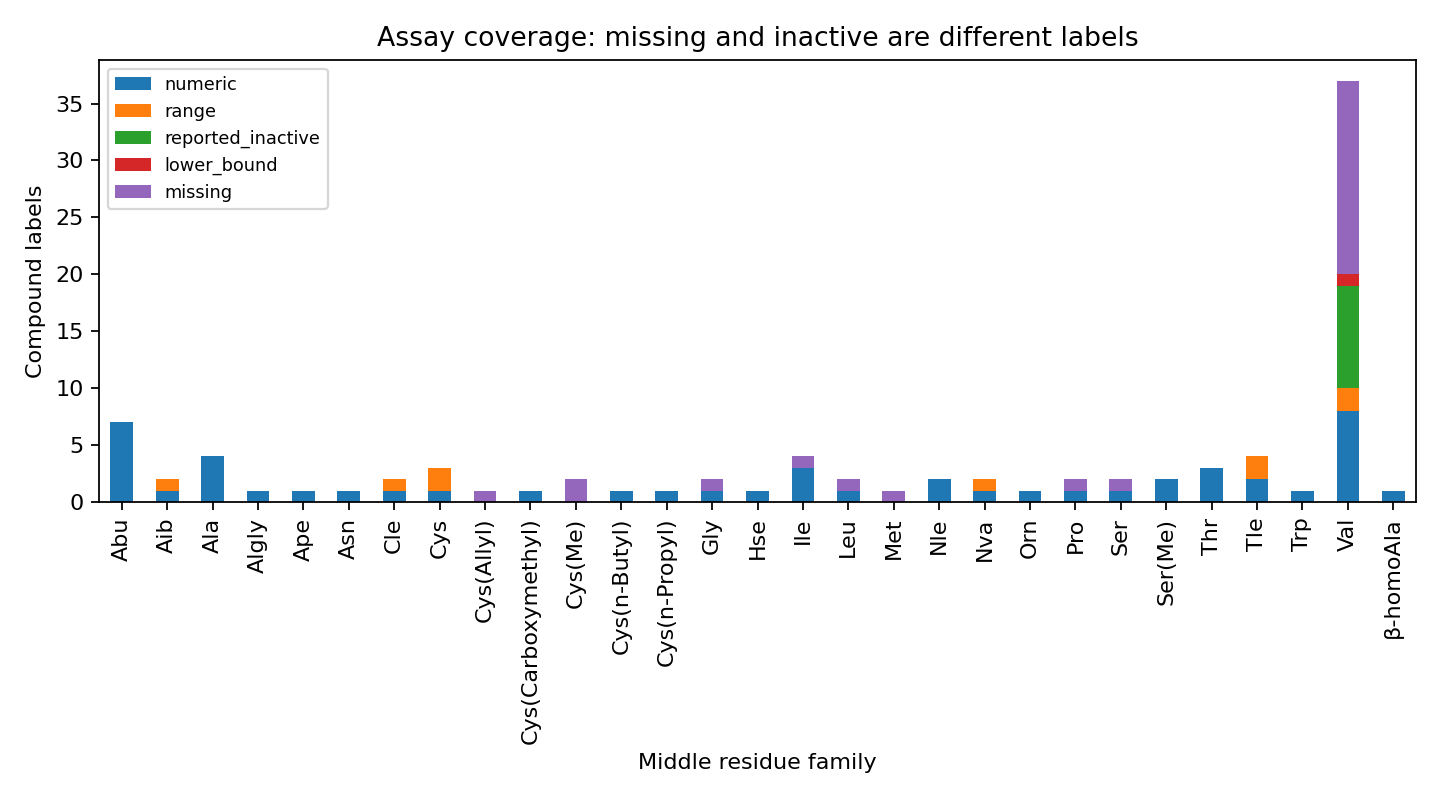

compound,hek293_raw,reason
γ-Glu-Tau,,No unambiguous monomer definition: Tau
γ-Glu-Cys(Me)(O),,No unambiguous monomer definition: Cys(Me)(O)
γ-Glu-Met(O),,No unambiguous monomer definition: Met(O)
γ-Glu-Val-NH 2,,No unambiguous monomer definition: NH2
γ-Glu-Val-OMe,,No unambiguous monomer definition: OMe
γ-Glu-Val-ol,,No unambiguous monomer definition: ol
γ-Glu-Pen-Gly,0.16–0.23,No unambiguous monomer definition: Pen
"γ-Glu-Cys(1,2-Dicarboxyethyl)-Gly",5–10,"No unambiguous monomer definition: Cys(1,2-Dicarboxyethyl)"


compound,reported_status,assay_system,source_location,doi,note,SMILES,formula
γ-Glu-Asp,reported_inactive_in_narrative,unspecified_in_sentence,Activities of gamma-glutamyl dipeptides,10.1248/cpb.c16-00293,Data not shown; no numerical EC50 or inactivity detection limit. Separate from HEK-293 table labels. Duplicate Asp name in source paragraph collapsed without guessing another identity.,N[C@@H](CCC(=O)N[C@@H](CC(=O)O)C(=O)O)C(=O)O,C9H14N2O7
γ-Glu-Gln,reported_inactive_in_narrative,unspecified_in_sentence,Activities of gamma-glutamyl dipeptides,10.1248/cpb.c16-00293,Data not shown; no numerical EC50 or inactivity detection limit. Separate from HEK-293 table labels. Duplicate Asp name in source paragraph collapsed without guessing another identity.,NC(=O)CC[C@H](NC(=O)CC[C@H](N)C(=O)O)C(=O)O,C10H17N3O6
γ-Glu-Glu,reported_inactive_in_narrative,unspecified_in_sentence,Activities of gamma-glutamyl dipeptides,10.1248/cpb.c16-00293,Data not shown; no numerical EC50 or inactivity detection limit. Separate from HEK-293 table labels. Duplicate Asp name in source paragraph collapsed without guessing another identity.,N[C@@H](CCC(=O)N[C@@H](CCC(=O)O)C(=O)O)C(=O)O,C10H16N2O7
γ-Glu-Lys,reported_inactive_in_narrative,unspecified_in_sentence,Activities of gamma-glutamyl dipeptides,10.1248/cpb.c16-00293,Data not shown; no numerical EC50 or inactivity detection limit. Separate from HEK-293 table labels. Duplicate Asp name in source paragraph collapsed without guessing another identity.,NCCCC[C@H](NC(=O)CC[C@H](N)C(=O)O)C(=O)O,C11H21N3O5
γ-Glu-His,reported_inactive_in_narrative,unspecified_in_sentence,Activities of gamma-glutamyl dipeptides,10.1248/cpb.c16-00293,Data not shown; no numerical EC50 or inactivity detection limit. Separate from HEK-293 table labels. Duplicate Asp name in source paragraph collapsed without guessing another identity.,N[C@@H](CCC(=O)N[C@@H](Cc1c[nH]cn1)C(=O)O)C(=O)O,C11H16N4O5


In [4]:
AUDIT_OUTPUTS=['data_audit.json','reconstructed_structures.csv','structure_exclusions.csv','assay_coverage_by_family.csv','assay_coverage.png','narrative_inactive_annotations.csv']
stage('data_audit','notebook_analysis.py',('audit',),tuple('results/notebook/'+p for p in AUDIT_OUTPUTS))
show_plot('assay_coverage.png')
show_table(REPORT/'structure_exclusions.csv')
show_table(REPORT/'narrative_inactive_annotations.csv',5)


## 5. Refit and evaluate the chemical models

Five fixed methods: training-set median; three neighbours weighted by squared Tanimoto similarity; Tanimoto kernel ridge (regularization 0.1); six-descriptor ridge (regularization 10); ExtraTrees (256 trees, minimum leaf size 2). Tanimoto measures overlap between fingerprint bits. Morgan fingerprints use radius 2, 2048 bits and chirality.

The main evaluation holds out the entire constitutional middle-residue family. Groups use canonical monomer connectivity without stereochemistry: Ile/allo-Ile and Thr/allo-Thr stay together, giving 26 groups. This tightens the earlier 28 name-based grouping. Random five-fold results are secondary and usually easier. All scaling and fitting occur on training folds. No test-fold tuning is performed.

Two source scenarios retain the journal assignments and the earlier patent assignments separately. They are not independent studies or extra replicates. Hyperparameters and the candidate combinations are exploratory choices, not a preregistered discovery trial.


Running: chemical_benchmark
chemical_benchmark: 19.5 seconds
 sensory validation or calibrated efficacy prediction."
}
version                   split            model  n  MAE_log10        R2  spearman  within_3fold
journal leave_middle_family_out           median 58   0.910516 -0.083138 -0.557995      0.379310
journal leave_middle_family_out         nearest3 58   0.798919  0.149646  0.427178      0.413793
journal leave_middle_family_out   tanimoto_ridge 58   0.885273  0.001612  0.395004      0.310345
journal leave_middle_family_out descriptor_ridge 58   0.915780 -0.094622 -0.024041      0.310345
journal leave_middle_family_out      extra_trees 58   0.830875  0.081387  0.427671      0.379310
                      name  ensemble_median_pEC50  model_spread_log10  middle_excluded_median_pEC50  nearest_similarity
  γ-Glu-Algly-L-Lacticacid               6.982537            1.002930                      6.782383            0.714286
    γ-Glu-Nva-L-Lacticacid               6.946543          

version,split,model,n,MAE_log10,R2,spearman,within_3fold,geometric_absolute_fold_error
journal,leave_middle_family_out,median,58,0.9105161888319744,-0.0831382162463532,-0.5579949417060713,0.3793103448275862,8.137971954504543
journal,leave_middle_family_out,nearest3,58,0.7989192149817639,0.1496459337632801,0.427178343509732,0.4137931034482758,6.293890965458944
journal,leave_middle_family_out,tanimoto_ridge,58,0.8852728646991181,0.0016124496674202,0.3950043835156605,0.3103448275862069,7.6784376961721135
journal,leave_middle_family_out,descriptor_ridge,58,0.9157797312580108,-0.0946224357677967,-0.0240406060168405,0.3103448275862069,8.237202284272524
journal,leave_middle_family_out,extra_trees,58,0.8308753651437633,0.0813872044927339,0.427670537618842,0.3793103448275862,6.774470643524332


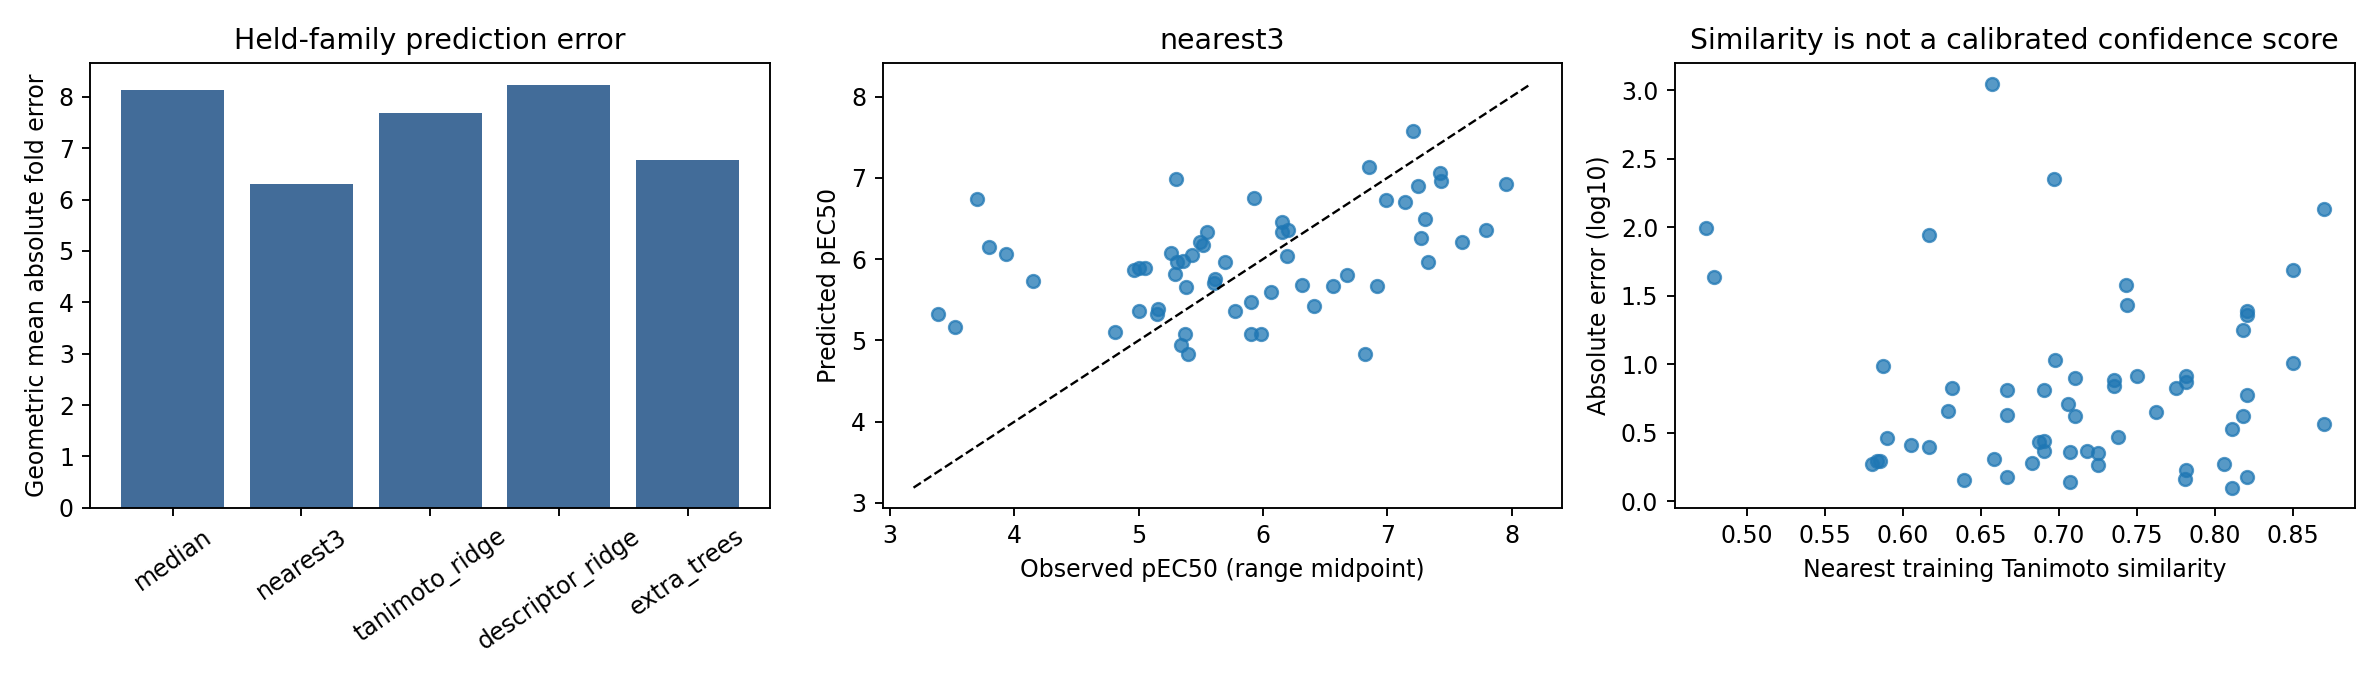

In [5]:
BENCH_OUTPUTS=['chemical_activity_dataset.csv','structure_exclusions.csv','model_metrics.csv','held_out_predictions.csv','candidate_predictions.csv','candidate_shortlist.csv','candidate_library.sdf','inactive_and_censored_diagnostic.csv','matched_glycine_extension_effects.csv','run_summary.json']
stage('chemical_benchmark','benchmark.py',outputs=tuple('results/'+p for p in BENCH_OUTPUTS),timeout=900)
ANALYSIS_OUTPUTS=['main_metrics.csv','bootstrap.json','held_family_errors.csv','family_errors.csv','interval_distance_metrics.csv','prediction_validation.png','matched_glycine_effects.csv','matched_chemical_effects.png','candidate_rank_sensitivity.csv','focused_comparison.csv','focused_structures.png','analysis_summary.json']
stage('chemical_analysis','notebook_analysis.py',('analyse',),tuple('results/notebook/'+p for p in ANALYSIS_OUTPUTS),timeout=600)
show_table(REPORT/'main_metrics.csv')
show_plot('prediction_validation.png')


### Read the error and inspect its causes

**MAE** (mean absolute error) averages `abs(predicted pEC50 − measured pEC50)`. `10**MAE` is the geometric mean absolute fold error; it is not a median error or a confidence interval. **R²** compares squared prediction error with a mean-value comparator; negative values are possible. **Spearman** measures rank association, not agreement in potency.

The bootstrap resamples 26 constitutional middle-residue families, keeping compounds within each family together. Its interval is descriptive: the lowest-error model was selected after reviewing the benchmark. Interval-distance error is an optimistic companion metric that assigns zero error inside a reported EC50 span; those spans are not confidence intervals.

Inspect the worst predictions and their nearest *training-fold* neighbours before trusting a new proposal. A fingerprint similarity score is not calibrated confidence.


In [6]:
print((REPORT/'bootstrap.json').read_text())
show_table(REPORT/'held_family_errors.csv',10)
show_table(REPORT/'family_errors.csv',10)
show_table(REPORT/'interval_distance_metrics.csv',10)


{
  "selected_model": "nearest3",
  "mean_error_reduction_log10": 0.11159697385021039,
  "percentile_95_interval": [
    -0.05464761987748431,
    0.2571954993026551
  ],
  "interpretation": "Descriptive cluster bootstrap; winner chosen after comparison; no multiplicity correction."
}
58 rows; showing 10 . Full CSV: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/work/casr_discovery/results/notebook/held_family_errors.csv
26 rows; showing 10 . Full CSV: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/work/casr_discovery/results/notebook/family_errors.csv
10 rows; showing 10 . Full CSV: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/work/casr_discovery/results/notebook/interval_distance_metrics.csv


version,split,fold,model,name,held_out_middle_family,middle_group_key,observed_pEC50,predicted_pEC50,absolute_error_log10,nearest_training_similarity
journal,leave_middle_family_out,23,nearest3,γ-Glu-Gly,Gly,NCC(=O)O,3.6989700043360183,6.745675396530031,3.046705392194013,0.6571428571428571
journal,leave_middle_family_out,16,nearest3,γ-Glu-Asn,Asn,NC(=O)CC(N)C(=O)O,3.7986028756795487,6.146835345129083,2.3482324694495342,0.696969696969697
journal,leave_middle_family_out,14,nearest3,γ-Glu-Cys(n-Propyl)-Gly,Cys(n-Propyl),CCCSCC(N)C(=O)O,3.9318141382538383,6.067347152606505,2.1355330143526667,0.8695652173913043
journal,leave_middle_family_out,22,nearest3,γ-Glu-Cle,Cle,NC1(C(=O)O)CCCC1,6.823908740944319,4.8324948796793725,1.9914138612649461,0.47368421052631576
journal,leave_middle_family_out,25,nearest3,γ-Glu-Pro,Pro,O=C(O)C1CCCN1,3.388276691992658,5.33013734669308,1.941860654700422,0.6170212765957447
journal,leave_middle_family_out,12,nearest3,γ-Glu-Nle-Gly,Nle,CCCCC(N)C(=O)O,5.301029995663981,6.988912323354627,1.6878823276906454,0.85
journal,leave_middle_family_out,21,nearest3,γ-Glu-Trp,Trp,NC(Cc1c[nH]c2ccccc12)C(=O)O,3.5228787452803374,5.160141032443418,1.6372622871630806,0.4791666666666667
journal,leave_middle_family_out,24,nearest3,γ-Glu-Orn,Orn,NCCCC(N)C(=O)O,4.152427340857888,5.73020272875479,1.577775387896902,0.7428571428571429
journal,leave_middle_family_out,5,nearest3,γ-Glu-Ala-Gly,Ala,CC(N)C(=O)O,7.795880017344075,6.360562796419154,1.4353172209249214,0.7435897435897436
journal,leave_middle_family_out,9,nearest3,γ-Glu-Abu-Gly,Abu,CCC(N)C(=O)O,7.602059991327962,6.211404482982806,1.390655508345156,0.8205128205128205


held_out_middle_family,n,MAE_log10
Gly,1,3.046705392194013
Asn,1,2.3482324694495342
Cys(n-Propyl),1,2.1355330143526667
Pro,1,1.941860654700422
Trp,1,1.6372622871630806
Orn,1,1.577775387896902
Cle,2,1.2263060969952648
Nle,2,1.1557469571193533
Nva,2,1.1272704748654023
Algly,1,1.0297462451968746


version,model,interval_distance_MAE_log10
journal,descriptor_ridge,0.8915509139350766
journal,extra_trees,0.8086064116638725
journal,median,0.8862873715090402
journal,nearest3,0.776533391791247
journal,tanimoto_ridge,0.8610440473761842
patent_assignment_sensitivity,descriptor_ridge,0.8920548201042189
patent_assignment_sensitivity,extra_trees,0.8127352998160959
patent_assignment_sensitivity,median,0.8862873715090404
patent_assignment_sensitivity,nearest3,0.774303353989905
patent_assignment_sensitivity,tanimoto_ridge,0.8556780574295797


## 6. Chemical effects and unmeasured combinations

Matched core/Gly comparisons ask whether appending a tail reliably improves activity. The interval ratios use the reported bounds; they are descriptive comparisons within a compiled series, not paired replicate statistics.

The candidate grid combines 14 represented middle residues with three tail classes, excluding combinations already present in the extracted series. Model/source rank ranges and middle-family exclusion sensitivity are reported. These forecasts cannot establish new activity, efficacy, safety or chemical novelty.

The Nva–L-lactic ester remains a **secondary unmeasured combination within an explicitly described scaffold**. The focused comparator set includes the known Val ester, Nva core and Nva-Gly. Its graph-predicted cleavage products do not establish hydrolysis rate or food stability.


7 rows; showing 7 . Full CSV: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/work/casr_discovery/results/notebook/matched_glycine_effects.csv
22 rows; showing 22 . Full CSV: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/work/casr_discovery/results/notebook/candidate_rank_sensitivity.csv


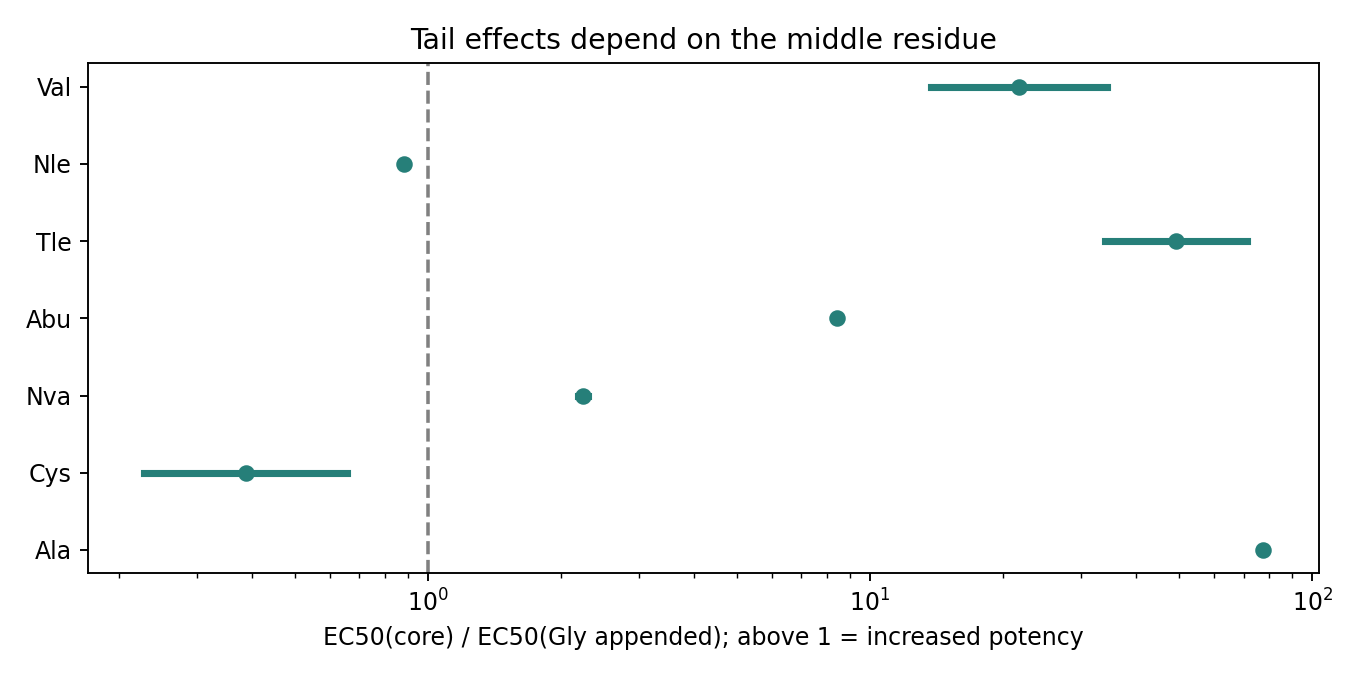

middle,dipeptide_EC50_low_uM,dipeptide_EC50_high_uM,glycine_appended_EC50_low_uM,glycine_appended_EC50_high_uM,glycine_potency_gain_low,glycine_potency_gain_high
Ala,1.24,1.24,0.016,0.016,77.5,77.5
Cys,0.16,0.46,0.7,0.7,0.2285714285714286,0.6571428571428573
Nva,0.12,0.12,0.052,0.055,2.1818181818181817,2.307692307692308
Abu,0.21,0.21,0.025,0.025,8.399999999999999,8.399999999999999
Tle,3.06,3.06,0.043,0.09,34.0,71.16279069767442
Nle,4.41,4.41,5.0,5.0,0.882,0.882
Val,1.03,1.03,0.03,0.075,13.733333333333334,34.333333333333336


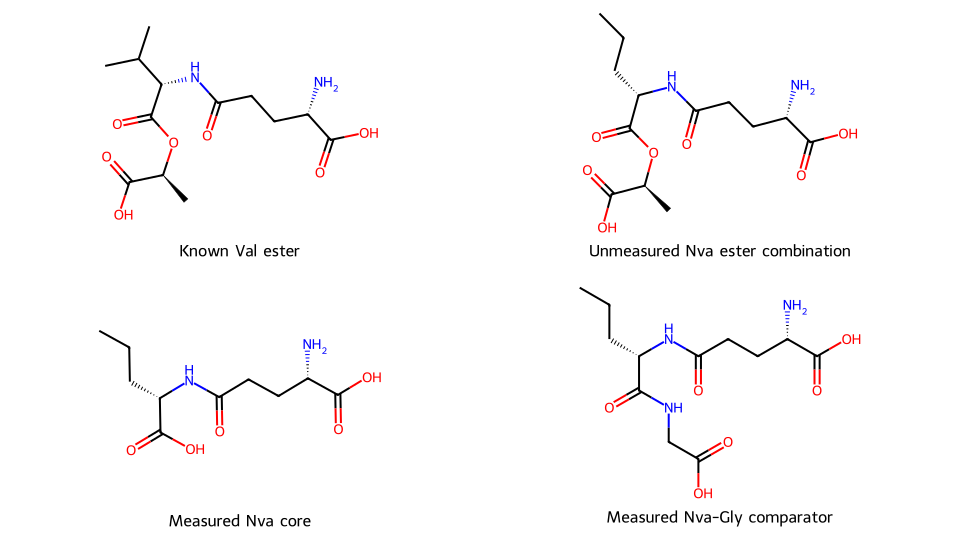

name,best_rank,worst_rank,min_forecast_uM,max_forecast_uM,SMILES,nearest_measured_compound,nearest_similarity,middle_excluded_median_pEC50,status
γ-Glu-Aib-Glycolicacid,11.0,21.0,0.104283327035458,2.2952962815704883,CC(C)(NC(=O)CC[C@H](N)C(=O)O)C(=O)OCC(=O)O,γ-Glu-Aib,0.6578947368421053,6.700078740487452,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Aib-L-Lacticacid,10.0,22.0,0.0805815189648321,4.185119174232184,C[C@H](OC(=O)C(C)(C)NC(=O)CC[C@H](N)C(=O)O)C(=O)O,γ-Glu-Aib,0.6756756756756757,6.755525805959099,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Ala-Glycolicacid,2.0,16.0,0.089570045250177,0.3433360635643099,C[C@H](NC(=O)CC[C@H](N)C(=O)O)C(=O)OCC(=O)O,γ-Glu-Val-Glycolicacid,0.7435897435897436,6.7282894203653845,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Ala-L-Lacticacid,5.0,12.0,0.0692814002716483,0.3446807770782658,C[C@H](NC(=O)CC[C@H](N)C(=O)O)C(=O)O[C@@H](C)C(=O)O,γ-Glu-Val-L-Lacticacid,0.7567567567567568,6.725583518058442,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Algly-Glycolicacid,2.0,18.0,0.0433764460911177,0.3676577786238652,C=CC[C@H](NC(=O)CC[C@H](N)C(=O)O)C(=O)OCC(=O)O,γ-Glu-Abu-Glycolicacid,0.6904761904761905,6.582523600052226,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Algly-L-Lacticacid,1.0,16.0,0.0364903685446957,0.3673735051757156,C=CC[C@H](NC(=O)CC[C@H](N)C(=O)O)C(=O)O[C@@H](C)C(=O)O,γ-Glu-Abu-L-Lacticacid,0.7142857142857143,6.782382871054194,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Cle-Glycolicacid,10.0,18.0,0.1092854869437015,0.9387565184845026,N[C@@H](CCC(=O)NC1(C(=O)OCC(=O)O)CCCC1)C(=O)O,γ-Glu-Cle,0.6829268292682927,6.349904832206677,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Cle-L-Lacticacid,6.0,17.0,0.0813391893446142,0.9396443292669444,C[C@H](OC(=O)C1(NC(=O)CC[C@H](N)C(=O)O)CCCC1)C(=O)O,γ-Glu-Cle,0.6829268292682927,6.552122302608661,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Cys-Glycolicacid,7.0,17.0,0.1317260754252386,0.3762005071586802,N[C@@H](CCC(=O)N[C@@H](CS)C(=O)OCC(=O)O)C(=O)O,γ-Glu-Cys,0.7027027027027027,6.595199735939101,Unmeasured in extracted series; described ester family; novelty not established
γ-Glu-Cys-L-Lacticacid,6.0,8.0,0.0687892611367597,0.2952653134222652,C[C@H](OC(=O)[C@H](CS)NC(=O)CC[C@H](N)C(=O)O)C(=O)O,γ-Glu-Cys,0.6842105263157895,6.798397304675573,Unmeasured in extracted series; described ester family; novelty not established


In [7]:
show_plot('matched_chemical_effects.png')
show_table(REPORT/'matched_glycine_effects.csv')
show_plot('focused_structures.png')
show_table(REPORT/'candidate_rank_sensitivity.csv',22)


## 7. Full docking panel and reference search

This is an actual calculation, not a file-format preflight. Twenty jobs include measured analogues, stereochemical controls, a weak α-linked comparator and three unmeasured combinations. Vina uses 2 CPU threads, seed 777, exhaustiveness 4 and up to 10 returned poses per compound. A separate native search uses exhaustiveness 16 and up to 20 poses.

Preparation regenerates the receptor from the supplied CIF. Four incomplete residues outside the binding box are omitted by the preparation rule. Ligand carboxylates are negative and free primary amines positive under one fixed hypothesis; no pKa has been measured here. This protocol uses a rigid binding domain and no modeled calcium ions in the deposited pocket.

**Redocking** removes the native ligand and searches its pose again. **Heavy-atom RMSD** measures displacement from the observed pose in the receptor coordinate frame; no alignment is applied to erase docking error. The closest returned pose and the top-scoring pose answer different questions.


Running: prepare_receptor
prepare_receptor: 2.7 seconds
_miss=set() bond_excess={4}
CGLH       heavy_miss=5 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess={1}

matched with excess inter-residue bond(s): A:481
No template matched for residue_key='A:499'
tried 6 templates for residue_key='A:499'excess_H_ok=False
GLU        heavy_miss=4 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess=set()
NGLU       heavy_miss=4 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess={4}
CGLU       heavy_miss=5 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess={1}
GLH        heavy_miss=4 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess=set()
NGLH       heavy_miss=4 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess={4}
CGLH       heavy_miss=5 heavy_excess=0 H_excess=[] bond_miss=set() bond_excess={1}

matched with excess inter-residue bond(s): A:499
No template matched for residue_key='A:500'
tried 6 templates for residue_key='A:500'excess_H_ok=False
ASP        heavy_miss=3 h

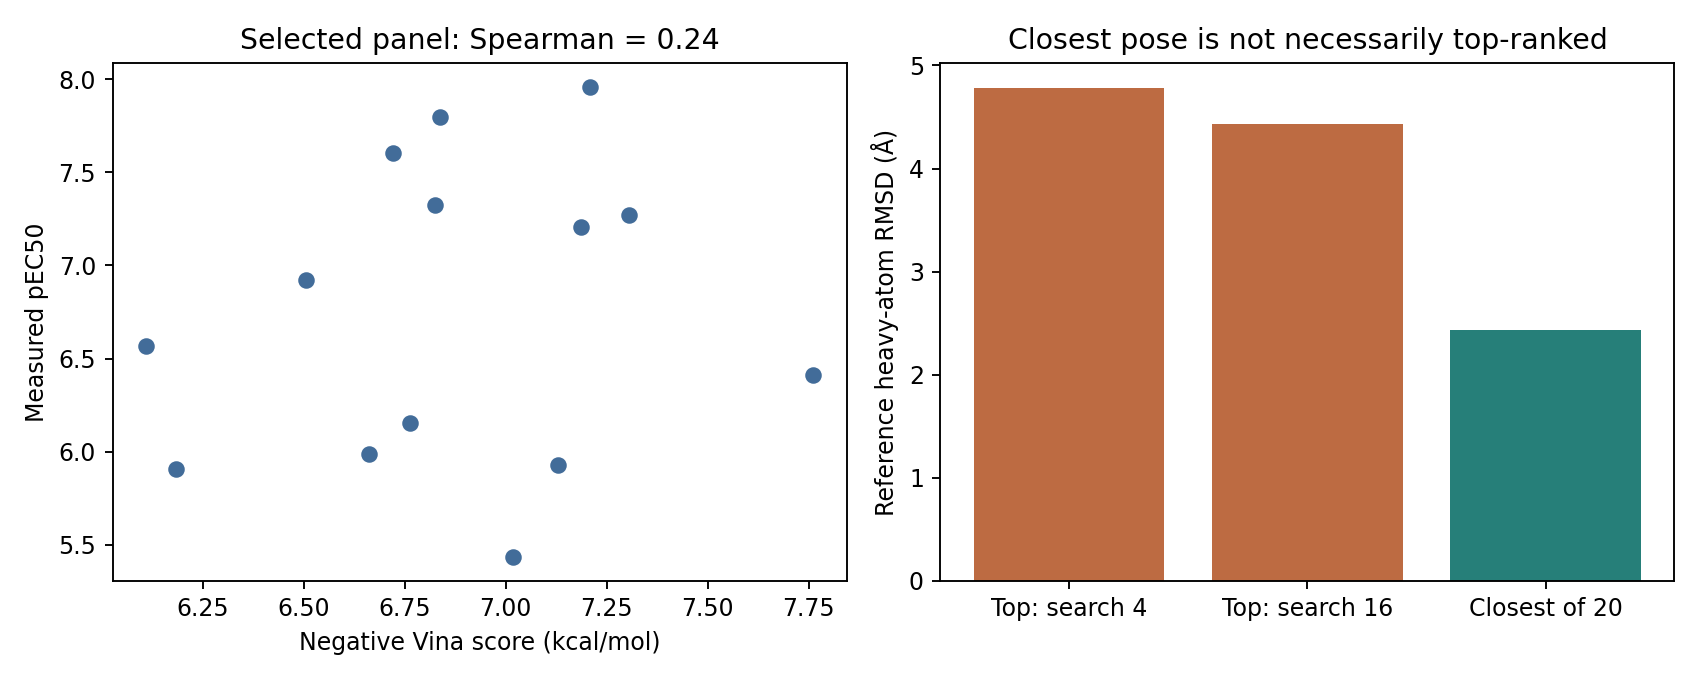

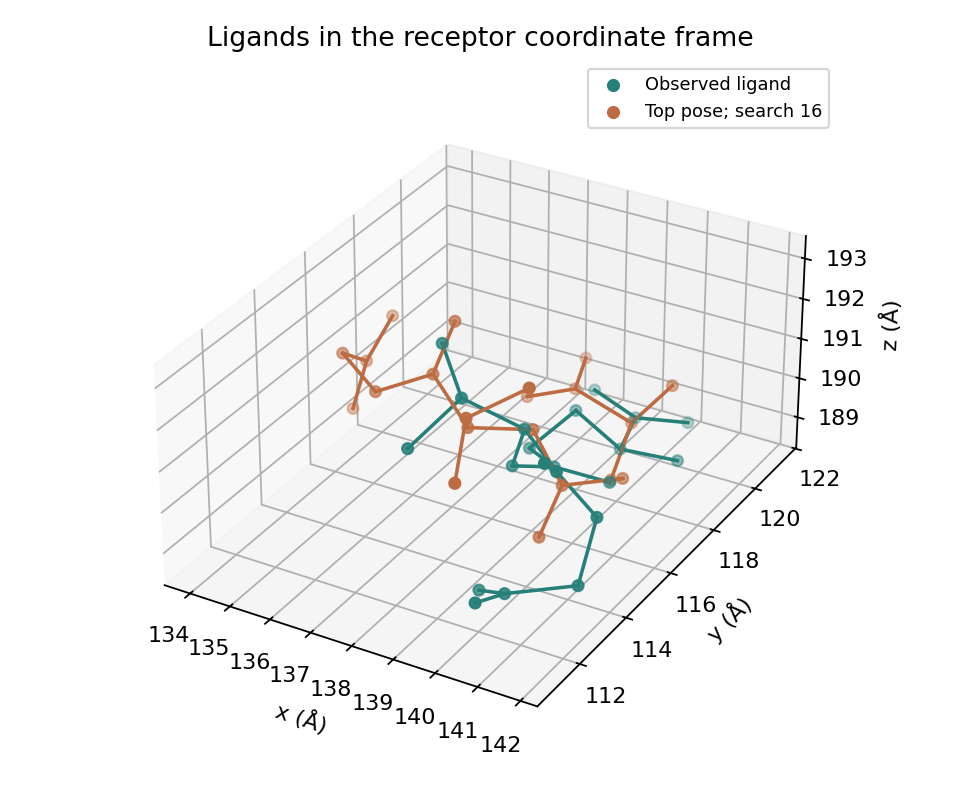

name,vina_top_score_kcal_mol,seconds,poses,mmff_initial_geometry_converged,native_top_rmsd_A,native_best_rmsd_A,hek293_status,EC50_low_uM,EC50_high_uM
γ-Glu-Val-Gly,-6.825,8.233469920000061,10,True,4.780330929033706,2.315842487214666,range,0.03,0.075
γ-Glu-Nva-Gly,-7.306,8.957084772999224,10,True,,,range,0.052,0.055
γ-Glu-Ala-Gly,-6.836,6.724377229000311,10,True,,,numeric,0.016,0.016
γ-Glu-Cys-Gly,-6.763,9.863229702000352,10,True,,,numeric,0.7,0.7
γ-Glu-Abu-Gly,-6.721,7.7726011680006195,10,True,,,numeric,0.025,0.025
γ-Glu-Tle-Gly,-7.187,8.636388266999347,10,True,,,range,0.043,0.09
γ-Glu-Algly-Gly,-7.209,9.584456778000458,10,True,,,numeric,0.011,0.011
γ-Glu-Hse-Gly,-7.129,10.133868033,10,True,,,numeric,1.18,1.18
γ-Glu-Val,-6.662,4.923533819000113,10,True,,,numeric,1.03,1.03
γ-Glu-Ala,-6.183,3.818157660999532,10,True,,,numeric,1.24,1.24


In [8]:
if RUN_DOCKING:
    stage('prepare_receptor','prepare_receptor.py',outputs=('results/casr.pdbqt','results/casr.json'),timeout=600)
    PANEL_OUTPUTS=['results/docking/'+p for p in ['run_summary.json','docking_results.csv','box.csv']]
    PANEL_OUTPUTS += [f'results/docking/{i:02d}.{suffix}' for i in range(20) for suffix in ['input.pdbqt','poses.pdbqt','poses.sdf']]
    stage('dock_20_compounds','docking.py',outputs=tuple(PANEL_OUTPUTS),timeout=2400,dependencies=('results/casr.pdbqt',))
    stage('native_search16','native_search_sensitivity.py',outputs=('results/docking/native_search_sensitivity.json','results/docking/native_exhaustiveness16.pdbqt'),timeout=900,dependencies=('results/casr.pdbqt',))
    DOCKING_MODE=STAGE_STATUS['dock_20_compounds']
    SOURCE_MODE='current'
    prefix='results/docking/'
else:
    DOCKING_MODE='archived_prior_run'
    SOURCE_MODE='archived'
    prefix='../prior_reference/docking/'
    print('ARCHIVED docking results from 14 October 2026; current-run docking files are left intact.')
DOCK_ANALYSIS_OUTPUTS=['docking_summary.json','docking_with_assay_labels.csv','docking_validation.png','native_pose_comparison.png']
stage('docking_analysis','notebook_analysis.py',('dock_analysis',SOURCE_MODE),tuple('results/notebook/'+p for p in DOCK_ANALYSIS_OUTPUTS),timeout=600,
      dependencies=tuple(prefix+p for p in ['docking_results.csv','native_search_sensitivity.json','native_exhaustiveness16.pdbqt','run_summary.json']))
(REPORT/'execution_mode.json').write_text(json.dumps({'docking_mode':DOCKING_MODE,'native_search_mode':STAGE_STATUS.get('native_search16','archived_prior_run'),'config':CONFIG},indent=2))
show_plot('docking_validation.png')
show_plot('native_pose_comparison.png')
show_table(REPORT/'docking_with_assay_labels.csv',20)


## 8. Decisions supported by this execution

A favourable docking score is not proof of agonism. A reported inactive compound may still bind. Score/activity association comes from a selected analogue panel, not a population-wide validation. Poor native pose recovery limits structural claims from this preparation and scoring protocol.

These models learn a receptor endpoint. They do not learn saltiness or sodium reduction. In Miyaki et al.'s chicken-consommé study, 5 ppm EVG altered other sensory attributes without a statistically significant saltiness change. Non-significance does not establish zero effect in every matrix.

Useful output is a reviewable chemical series, its measured boundaries, prediction failures and specific comparator choices. New findings require independent evidence. The candidate is not promoted as a hit simply because it has a high forecast.


In [9]:
stage('research_decisions','notebook_analysis.py',('decision',),('results/notebook/research_decisions.md',),dependencies=('results/notebook/execution_mode.json','results/notebook/docking_summary.json','results/notebook/analysis_summary.json'))
print((REPORT/'research_decisions.md').read_text())


Running: research_decisions
research_decisions: 1.0 seconds
# Executed CaSR notebook: research decisions

Best observed chemical-family model MAE: 0.799 log10; geometric mean absolute fold error: 6.29.
The descriptive bootstrap does not establish a reliable advantage over the median comparator. Random folds are secondary; they do not establish external generalization.

Docking source: computed_this_execution. 20 compound results, 14 numeric assay comparisons; score/activity Spearman 0.240.
Top native RMSD 4.78 Å, larger-search top 4.44 Å, closest returned pose 2.43 Å. The top-ranked reference pose remains displaced; this protocol is weak support for structural prioritization.

What can be used: explicit structures, assay labels, matched chemical effects, failure examples and reproducible comparison conditions.
What remains unknown: activity of the proposed compounds, taste effects, food stability and suitability.

The Nva ester is an unmeasured combination within an explicitly describe

## 9. Export a complete review package

The ZIP includes readable source, curated inputs, versions, folds, forecasts, figures, poses and logs. The environment itself is excluded. Results are written to disk after each compound so completed docking jobs can be inspected if a runtime is interrupted; a failed stage is not marked complete.


In [10]:
import zipfile
EXPORT=BASE/'CaSR_Notebook_Run.zip'
with zipfile.ZipFile(EXPORT,'w',zipfile.ZIP_DEFLATED) as z:
    for folder in [WORK,LOGS]:
        for path in sorted(folder.rglob('*')):
            if path.is_file() and '__pycache__' not in path.parts:
                z.write(path,path.relative_to(BASE))
print('Export:',EXPORT,'| bytes:',EXPORT.stat().st_size)
display(FileLink(str(EXPORT)))
try:
    from google.colab import files
except ImportError:
    files=None
if files is not None:
    print('Download by running: files.download(str(EXPORT))')


Export: /workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/CaSR_Notebook_Run.zip | bytes: 1980515


/workspace/scratch/cadb742a5030/research/notebook_validation/casr_research_run/CaSR_Notebook_Run.zip

## Sources and reproducibility boundaries

1. Amino Y, et al. (2016). *Structure–CaSR–Activity Relation of Kokumi γ-Glutamyl Peptides*. Chemical and Pharmaceutical Bulletin 64(8), 1181–1189. [doi:10.1248/cpb.c16-00293](https://doi.org/10.1248/cpb.c16-00293). [2017 erratum](https://doi.org/10.1248/cpb.c17-e6506) corrects source attribution for γ-Glu-Abu; it does not resolve the six hydroxy-acid assignments.
2. Eto Y, Amino Y. *Kokumi-imparting agent*. [US20100136197A1](https://patents.google.com/patent/US20100136197A1/en), published 3 June 2010. Table 3 is retained as a label-assignment sensitivity scenario. The ester family and norvaline definition are explicitly described.
3. Yamaguchi H, et al. (2025). *Cryo-EM structure of the calcium-sensing receptor complexed with the kokumi substance γ-glutamyl-valyl-glycine*. Scientific Reports 15, 3894. [doi:10.1038/s41598-025-87999-1](https://doi.org/10.1038/s41598-025-87999-1); [PDB 9J7I](https://www.rcsb.org/structure/9J7I).
4. Miyaki T, et al. (2015). *Effect of a kokumi peptide, γ-glutamyl-valyl-glycine, on the sensory characteristics of chicken consommé*. Flavour 4, 17. [doi:10.1186/2044-7248-4-17](https://doi.org/10.1186/2044-7248-4-17).
5. [AutoDock Vina documentation](https://autodock-vina.readthedocs.io/en/latest/); [RDKit documentation](https://www.rdkit.org/docs/); [scikit-learn model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html).

The curated table is supplied so analysis does not depend on live scraping. Consult `source_notes.json` and the original documents when auditing labels. No full publisher article or patent is redistributed. Exact package versions and input hashes are exported. This is exploratory analysis, not an independently validated sensory predictor or a claim of chemical novelty.
